# Session 04 · Can the final residual stage learn better food features?

In Session 03, the frozen ImageNet backbone scored 0.5146 validation macro F1. It called 44 of 100 hamburgers pulled pork sandwiches. I want to know whether letting the later filters adapt to food helps more than spending the same training budget on the classifier alone.

I start two runs from the selected Session 03 weights (epoch 7). Each gets three more passes through the same 65,624 training images. I compare their validation scores at equal epochs and inspect the photos on which their predictions disagree. **Run all** on a Colab GPU. Checkpoints go to separate folders in Drive. A fresh runtime can resume the last completed epoch for either run.

In [1]:
import torch
if not torch.cuda.is_available():
    raise RuntimeError("Select a GPU runtime for full training, then run again.")
device = torch.device("cuda")
print("Training GPU:", torch.cuda.get_device_name(device))

Training GPU: Tesla T4


In [2]:
from pathlib import Path
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/Colab Notebooks/Project 03 - Intelligent Food and Retail Product Recognition")
    sys.path.insert(0, str(PROJECT))
    from colab_food101 import stage_food
    ROOT = stage_food(PROJECT, Path("/content/project03_data"))
else:
    PROJECT = Path.cwd()
    ROOT = PROJECT / "Dataset/food-101"

Mounted at /content/drive


## Keep the input pipeline fixed

I use the saved split, 224-pixel crops, flips and batches of 64 from Session 03. Each arm uses the same seed for each epoch. This pairs the sampled training images and crops. Validation has 100 photos per dish and a deterministic center crop. The official test images are reserved for the final project evaluation.

In [3]:
import hashlib
import json
import math
import time
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Dataset
import torchvision
from torchvision import transforms as T
from torchvision.models import resnet18, ResNet18_Weights

artifacts = PROJECT / "Artifacts"
manifest_path = artifacts / "split_manifest.csv"
fingerprint = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
assert fingerprint == "86555fa81dd85aebd59d725ab89148a8a7596430889094e4566f917fe6f451fc"
table = pd.read_csv(manifest_path)
class_map = json.loads((artifacts / "class_map.json").read_text())
assert table.dish.map(class_map).eq(table.class_id).all()
classes = sorted(class_map, key=class_map.get)
assert len(classes) == 101 and [class_map[k] for k in classes] == list(range(101))
train_rows = table.loc[table.split.eq("train")]
val_rows = table.loc[table.split.eq("validation")]
assert (len(train_rows), len(val_rows)) == (65624, 10100)
eval_transform = ResNet18_Weights.IMAGENET1K_V1.transforms()
train_transform = T.Compose([T.RandomResizedCrop(224, scale=(0.7, 1.0)), T.RandomHorizontalFlip(),
                             T.ToTensor(), T.Normalize(eval_transform.mean, eval_transform.std)])

class Photos(Dataset):
    def __init__(self, rows, transform):
        self.records = list(rows[["path", "class_id"]].itertuples(index=False, name=None))
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        path, label = self.records[index]
        with Image.open(ROOT / path) as photo:
            return self.transform(photo.convert("RGB")), label

train_set = Photos(train_rows, train_transform)
val_set = Photos(val_rows, eval_transform)
BATCH = 64
WORKERS = 2
SEED = 42
def loader(dataset, training, epoch=0):
    generator = torch.Generator().manual_seed(SEED + epoch)
    return DataLoader(dataset, batch_size=BATCH, shuffle=training, generator=generator,
                      num_workers=WORKERS, pin_memory=device.type == "cuda")

print(len(train_set), "training photos and", len(val_set), "validation photos")

65624 training photos and 10100 validation photos


## Unfreeze one stage

ResNet-18’s `layer4` is its final **stage**. It contains two residual blocks before pooling and the linear classifier, `fc`. Earlier layers can keep their existing filters while these later blocks learn combinations that distinguish dishes. Training only `fc` is cheaper. Unfreezing the whole network is another alternative and belongs in the next experiment.

Both runs use fresh SGD momentum because the saved best model contains weights. I set the head learning rate to 0.003 for both runs. In the partial run, `layer4` gets 0.0003 so its pretrained weights move more gradually. These are **parameter groups**. They let one optimizer assign different step sizes to different layers. The PyTorch tutorial illustrates two common recipes, training only the last layer and fine-tuning the whole model. Here I try the middle ground. I keep batch-normalization running statistics fixed in both runs. In the partial run the scale and offset parameters inside `layer4` can learn. [PyTorch transfer-learning tutorial](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html)

In [4]:
source_dir = artifacts / "session03_resnet18_frozen"
source_file = source_dir / "best.pt"
source_hash = hashlib.sha256(source_file.read_bytes()).hexdigest()
assert source_hash == "6d1b90e58d8732770e4835dd65e5c3cda78cd76101eff149e479fbe7f4e0583a"
source = torch.load(source_file, map_location="cpu", weights_only=True)
prior = json.loads((source_dir / "validation.json").read_text())
assert source["classes"] == prior["class_order"] == classes
assert source["epoch"] == prior["selected_epoch"] == 7
assert source["config"]["manifest"] == prior["config"]["manifest"] == fingerprint
EPOCHS = 3
HEAD_LR, STAGE_LR = 0.003, 0.0003
ARMS = ("head_only", "layer4_and_head")
out = artifacts / "session04_partial_finetuning"
out.mkdir(exist_ok=True)
use_amp = device.type == "cuda"

def build(arm):
    if arm not in ARMS:
        raise ValueError(arm)
    net = resnet18(weights=None, num_classes=len(classes))
    net.load_state_dict(source["weights"])
    net.requires_grad_(False)
    net.fc.requires_grad_(True)
    if arm == "layer4_and_head":
        net.layer4.requires_grad_(True)
    # Evaluation mode fixes BN running statistics. Gradients still follow requires_grad.
    return net.to(device).eval()

def optimizer_for(net, arm):
    groups = [{"params": net.fc.parameters(), "lr": HEAD_LR}]
    if arm == "layer4_and_head":
        groups.append({"params": net.layer4.parameters(), "lr": STAGE_LR})
    return torch.optim.SGD(groups, lr=HEAD_LR, momentum=0.9, weight_decay=1e-4)

for arm in ARMS:
    net = build(arm)
    print(arm, "trainable parameters:", sum(p.numel() for p in net.parameters() if p.requires_grad))
    del net

head_only trainable parameters: 51813
layer4_and_head trainable parameters: 8445541


## Save each completed epoch and check what changed

After every epoch I check the frozen tensors against the starting checkpoint, including batch-normalization buffers. Each run saves its optimizer state, current trainable weights, history, and best trainable weights together. The highest validation macro F1 selects the checkpoint within each run. Epoch numbers below count additional training since the shared starting point.

In [5]:
def train_batch(net, optimizer, scaler, batch):
    images, labels = (value.to(device, non_blocking=True) for value in batch)
    optimizer.zero_grad(set_to_none=True)
    with torch.autocast(device_type=device.type, enabled=use_amp):
        loss = nn.functional.cross_entropy(net(images), labels)
    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()
    return loss.detach(), len(labels)

def save_checkpoint(value, path):
    pending = path.with_suffix(".pending")
    torch.save(value, pending)
    pending.replace(path)

In [6]:
def evaluate_with_predictions(net):
    net.eval()
    actual, predicted = [], []
    top5, total_loss = 0, 0.0
    with torch.inference_mode():
        for images, labels in loader(val_set, False):
            images, labels = images.to(device), labels.to(device)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                logits = net(images)
                loss = nn.functional.cross_entropy(logits, labels, reduction="sum")
            top = logits.topk(5, dim=1).indices
            actual.append(labels.cpu())
            predicted.append(top[:, 0].cpu())
            top5 += int(top.eq(labels[:, None]).any(dim=1).sum())
            total_loss += loss.item()
    actual, predicted = torch.cat(actual), torch.cat(predicted)
    k = len(classes)
    matrix = torch.bincount(k * actual + predicted, minlength=k*k).reshape(k, k)
    assert torch.equal(actual, torch.tensor([label for _, label in val_set.records]))
    f1 = 2 * matrix.diag() / (matrix.sum(0) + matrix.sum(1)).clamp_min(1)
    scores = dict(val_loss=total_loss/len(actual), top1=matrix.diag().sum().item()/len(actual),
                  top5=top5/len(actual), macro_f1=f1.mean().item())
    return scores, matrix, predicted

def train_arm(arm, stop_epoch=EPOCHS):
    folder = out / arm
    folder.mkdir(exist_ok=True)
    latest = folder / "latest.pt"
    net = build(arm)
    opt = optimizer_for(net, arm)
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)
    trainable = {name for name, p in net.named_parameters() if p.requires_grad}
    recipe = dict(arm=arm, source=source_hash, manifest=fingerprint, seed=SEED, batch=BATCH,
                  workers=WORKERS, crop=224, head_lr=HEAD_LR, stage_lr=STAGE_LR,
                  momentum=0.9, weight_decay=1e-4, amp=use_amp, bn="fixed", version=1)
    history, best = [], None
    if latest.is_file():
        saved = torch.load(latest, map_location="cpu", weights_only=True)
        assert saved["recipe"] == recipe and set(saved["current"]) == trainable
        net.load_state_dict({**source["weights"], **saved["current"]})
        opt.load_state_dict(saved["optimizer"])
        scaler.load_state_dict(saved["scaler"])
        history, best = saved["history"], saved["best"]
        del saved
    for epoch in range(len(history) + 1, stop_epoch + 1):
        data_epoch = source["epoch"] + epoch
        torch.manual_seed(SEED + data_epoch)
        net.eval()
        start = time.perf_counter()
        total = torch.zeros((), device=device)
        seen = batches = 0
        for batch in loader(train_set, True, data_epoch):
            loss, n = train_batch(net, opt, scaler, batch)
            total += loss * n
            seen += n
            batches += 1
        train_loss = total.item() / seen
        assert seen == len(train_set) and batches == math.ceil(seen / BATCH)
        train_seconds = time.perf_counter() - start
        start = time.perf_counter()
        scores, matrix, preds = evaluate_with_predictions(net)
        val_seconds = time.perf_counter() - start
        assert math.isfinite(train_loss) and all(math.isfinite(v) for v in scores.values())
        current = {}
        for name, value in net.state_dict().items():
            if name in trainable:
                current[name] = value.detach().cpu().clone()
            else:
                assert torch.equal(value.cpu(), source["weights"][name]), name
        assert not torch.equal(current["fc.weight"], source["weights"]["fc.weight"])
        if arm == "layer4_and_head":
            key = "layer4.0.conv1.weight"
            assert not torch.equal(current[key], source["weights"][key])
        row = dict(epoch=epoch, batches=batches, train_loss=train_loss, train_seconds=train_seconds,
                   validation_seconds=val_seconds, **scores)
        history.append(row)
        if best is None or scores["macro_f1"] > best["scores"]["macro_f1"]:
            best = dict(epoch=epoch, scores=scores, weights=current, matrix=matrix, predictions=preds)
        save_checkpoint(dict(recipe=recipe, current=current, optimizer=opt.state_dict(),
                             scaler=scaler.state_dict(), history=history, best=best), latest)
        print(arm, row, flush=True)
    net.load_state_dict({**source["weights"], **best["weights"]})
    scores, matrix, preds = evaluate_with_predictions(net)
    assert torch.equal(preds, best["predictions"]) and torch.equal(matrix, best["matrix"])
    save_checkpoint(dict(weights=net.cpu().state_dict(), classes=classes, config=recipe,
                         epoch=best["epoch"]), folder / "best.pt")
    return dict(history=history, selected_epoch=best["epoch"], scores=scores,
                matrix=matrix.tolist(), predictions=preds.tolist())

results = {arm: train_arm(arm) for arm in ARMS}

head_only {'epoch': 1, 'batches': 1026, 'train_loss': 1.4952823090637573, 'train_seconds': 356.1097593150001, 'validation_seconds': 56.77462477100005, 'val_loss': 1.7349761301928228, 'top1': 0.5795049504950495, 'top5': 0.823069306930693, 'macro_f1': 0.5785990953445435}
head_only {'epoch': 2, 'batches': 1026, 'train_loss': 1.4494781587147996, 'train_seconds': 340.57459947099994, 'validation_seconds': 57.503890971000146, 'val_loss': 1.7112460361140789, 'top1': 0.5846534653465346, 'top5': 0.8215841584158415, 'macro_f1': 0.5829023122787476}
head_only {'epoch': 3, 'batches': 1026, 'train_loss': 1.4351669882588687, 'train_seconds': 322.591076894, 'validation_seconds': 52.616736978999825, 'val_loss': 1.7004417413768202, 'top1': 0.5843564356435643, 'top5': 0.8216831683168316, 'macro_f1': 0.5808855891227722}
layer4_and_head {'epoch': 1, 'batches': 1026, 'train_loss': 1.4616771541280629, 'train_seconds': 320.35163747, 'validation_seconds': 52.2721303809999, 'val_loss': 1.5646487511738691, 'top1'

## Did adapting the features help?

The final-epoch comparison gives both arms the same number of training examples and optimizer steps. I also report each arm’s best validation checkpoint and compare it with Session 03. I count the earlier hamburger and Greek salad errors, then show photos that changed from wrong to right or right to wrong. These are paired predictions for the very same validation images.

           model  epoch   top1   top5  macro_f1  hamburger → pulled_pork_sandwich  greek_salad → caprese_salad
Session 03 start      7 0.5181 0.7798    0.5146                                44                            3
       head_only      2 0.5847 0.8216    0.5829                                 9                            9
 layer4_and_head      3 0.6303 0.8563    0.6289                                 3                            9

Equal-budget final epochs
            arm  epoch     top1     top5  macro_f1
      head_only      3 0.584356 0.821683  0.580886
layer4_and_head      3 0.630297 0.856337  0.628864
Paired changes from the head-only to the partial checkpoint: {'corrected': 869, 'regressed': 408}


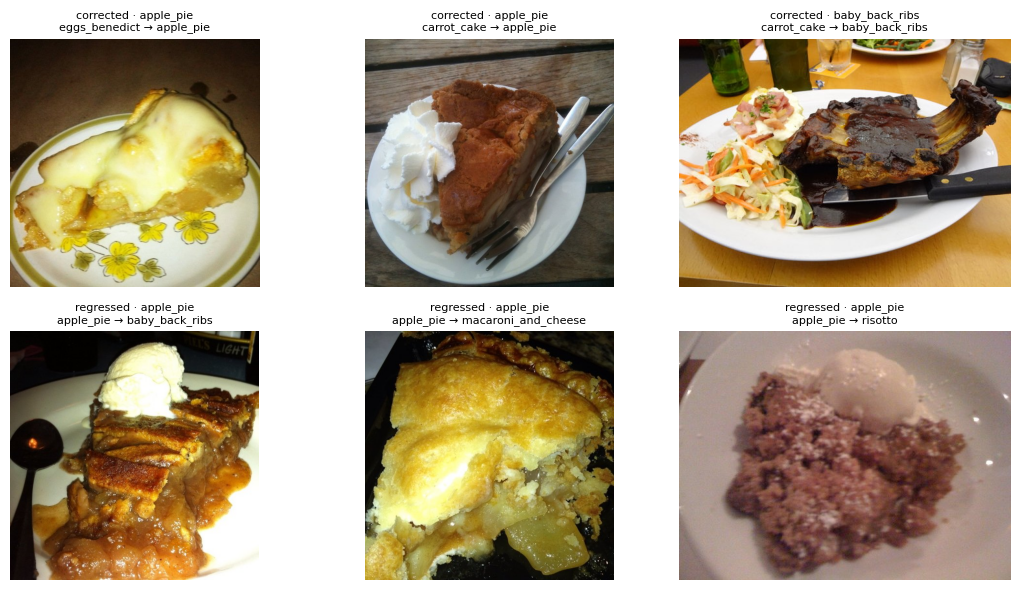

Saved both selected models, predictions, and comparison to /content/drive/MyDrive/Colab Notebooks/Project 03 - Intelligent Food and Retail Product Recognition/Artifacts/session04_partial_finetuning


In [7]:
pairs = [("hamburger", "pulled_pork_sandwich"), ("greek_salad", "caprese_salad")]
def summary_row(label, epoch, scores, matrix):
    row = dict(model=label, epoch=epoch, **{k: scores[k] for k in ("top1", "top5", "macro_f1")})
    for a, b in pairs:
        row[f"{a} → {b}"] = matrix[class_map[a]][class_map[b]]
    return row

rows = [summary_row("Session 03 start", source["epoch"], prior["validation"], prior["confusion_matrix"])]
for arm, result in results.items():
    rows.append(summary_row(arm, result["selected_epoch"], result["scores"], result["matrix"]))
print(pd.DataFrame(rows).round(4).to_string(index=False))
matched = pd.DataFrame([dict(arm=arm, **row) for arm in ARMS for row in results[arm]["history"]])
print("\nEqual-budget final epochs")
print(matched.groupby("arm").tail(1)[["arm","epoch","top1","top5","macro_f1"]].to_string(index=False))
predictions = val_rows[["path", "dish", "class_id"]].reset_index(drop=True).copy()
for arm in ARMS:
    predictions[arm] = results[arm]["predictions"]
control_right = predictions.head_only.eq(predictions.class_id)
partial_right = predictions.layer4_and_head.eq(predictions.class_id)
changes = {"corrected": ~control_right & partial_right, "regressed": control_right & ~partial_right}
counts = {label: int(mask.sum()) for label, mask in changes.items()}
print("Paired changes from the head-only to the partial checkpoint:", counts)

fig, axes = plt.subplots(2, 3, figsize=(11, 6), squeeze=False)
for row, (label, mask) in enumerate(changes.items()):
    for ax in axes[row]:
        ax.axis("off")
    for ax, sample in zip(axes[row], predictions[mask].head(3).itertuples()):
        with Image.open(ROOT / sample.path) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(f"{label} · {sample.dish}\n{classes[sample.head_only]} → {classes[sample.layer4_and_head]}", fontsize=8)
fig.tight_layout()
fig.savefig(out / "paired_changes.png")
plt.show()

predictions.to_csv(out / "validation_predictions.csv", index=False)
report = dict(source_sha256=source_hash, manifest=fingerprint, device=str(device),
              gpu=torch.cuda.get_device_name() if use_amp else None, torch=str(torch.__version__),
              torchvision=str(torchvision.__version__), class_order=classes, paired_changes=counts,
              comparison=rows, arms={arm:{k:v for k,v in r.items() if k!="predictions"}
                                      for arm,r in results.items()})
pending = out / "validation.json.tmp"
pending.write_text(json.dumps(report,indent=2), encoding="utf-8")
pending.replace(out / "validation.json")
print("Saved both selected models, predictions, and comparison to", out)